# La malla de tamices, el P80 por interpolación y el oráculo en x63

**Pregunta:** ¿Qué tan grande es el error de leer un tamaño de la malla de tamices del motor por interpolación, cómo se reduce con una malla más fina, y concuerda el motor con la ley de forma cerrada una vez que se considera el tamaño máximo de la malla?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el notebook 01 de este tema
- **Tiempo de lectura:** unos 35 minutos

## Objetivos

Al terminar este notebook usted puede:

- construir la malla de raíz de dos y comprobar su razón y los tamaños medios de sus clases;
- convertir las masas de clase de una alimentación en una curva de pasante acumulado, y decir cómo funciona la normalización;
- leer un tamaño para una fracción pasante y una fracción pasante para un tamaño, y enunciar la regla de interpolación de cada lectura;
- medir el error de interpolación frente a una referencia exacta, y mostrar que baja al refinar la malla;
- comprobar el motor contra el oráculo en x63, corrigiendo el oráculo por el tamaño máximo de la malla.

## Preparación

Las dos bibliotecas del conjunto, numpy y matplotlib.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

La celda importa las utilidades de malla e interpolación del motor (`model/crusher/sieve.py`, `feed.py`) y la ley de forma cerrada del oráculo, con nombres que la mantienen separada de las funciones del motor que se llaman igual.

In [1]:
# Imprima las versiones de las herramientas de este notebook, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# El notebook está tres carpetas bajo la raíz del repositorio; el pipeline se importa por su ruta
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
import math

from pipeline.model.crusher.feed import make_feed
from pipeline.model.crusher.sieve import make_grid, mid_sizes, cumulative_passing, to_psd, size_at_passing, passing_at_size
from pipeline.oracles import rosin_rammler_passing as law_passing
from pipeline.oracles import rosin_rammler_size_at as law_size_at
from pipeline.oracles import rosin_rammler_x63_passing as law_at_x63
from pipeline.oracles import mass_closure
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Datos

La alimentación del caso de referencia S01, como en el notebook 01. Propietario: este repositorio, https://github.com/fsantibanezleal/CAOS_ChancaDEM. Clase de licencia: MIT; los artefactos versionados los escribe el pipeline a partir de los parámetros de cada caso. Archivo leído: `data/derived/manifests/S01.json`, bloque `params`.

La celda lee los parámetros de la alimentación.

In [2]:
# Lea x63 y m de la alimentación de referencia
params = json.loads((ROOT / "data" / "derived" / "manifests" / "S01.json").read_text(encoding="utf-8"))["params"]
X63, M = params["feed_x63_mm"], params["feed_m"]
print(f"x63 = {X63} mm, m = {M}")

x63 = 90.0 mm, m = 1.2


## Método

**Paso 1, la malla.** La malla del motor es la serie estándar de laboratorio: cada borde es el anterior dividido por $\sqrt 2$, desde 256 mm, 29 bordes para 28 clases. El tamaño medio de la clase $i$ es la media geométrica de sus bordes, $\sqrt{e_i e_{i+1}}$, el centro natural en una escala de razón. La celda construye la malla y comprueba que cada razón consecutiva es $\sqrt 2$ y que cada tamaño medio queda $2^{-1/4}$ bajo el borde superior.

In [3]:
# Construya la malla y compruebe su estructura geométrica
edges = make_grid(256, 28)
mids = mid_sizes(edges)
ratios = np.array(edges[:-1]) / np.array(edges[1:])
print("bordes:", len(edges), "| clases:", len(mids))
print("razón mínima y máxima:", ratios.min().round(12), ratios.max().round(12), "| raíz de 2 =", round(math.sqrt(2), 12))
print("medio / borde superior:", (np.array(mids) / np.array(edges[:-1])).round(6)[:3], "| 2^(-1/4) =", round(2 ** -0.25, 6))

bordes: 29 | clases: 28
razón mínima y máxima: 1.414213562373 1.414213562373 | raíz de 2 = 1.414213562373
medio / borde superior: [0.840896 0.840896 0.840896] | 2^(-1/4) = 0.840896


**Paso 2, de masas de clase a una curva de pasante.** La masa de una clase es la diferencia de la ley entre sus bordes, y el motor convierte las 28 masas en una curva acumulada en dos movimientos. `to_psd` renormaliza las masas para que sumen 1, lo que hace que la curva termine en 100 por ciento en el borde superior; `cumulative_passing` luego acumula desde la clase más fina hacia arriba, de modo que el pasante en un borde es la masa de todas las clases bajo él. La celda construye la alimentación de S01 y muestra ambas normalizaciones: la suma cruda de las masas de clase, que es $R(256)$ porque todo lo que está sobre el borde superior falta, y la renormalizada.

In [4]:
# Masas de clase crudas de la ley, su suma, y la alimentación renormalizada que usa el motor
raw = [law_passing(edges[i], X63, M) - law_passing(edges[i + 1], X63, M) for i in range(28)]
feed = to_psd(edges, raw)
print("suma de las masas crudas:", round(sum(raw), 6), "| R(256) de la ley:", round(law_passing(256, X63, M), 6))
print("suma tras to_psd:", round(sum(feed.mass), 12), "| oráculo de cierre de masa:", mass_closure([1.0], list(feed.mass)))
same = make_feed(edges, X63, M)
print("make_feed da las mismas masas:", np.allclose(same.mass, feed.mass, rtol=0, atol=1e-15))
print("pasante en el borde superior:", feed.passing[0], "| en el borde inferior:", feed.passing[-1])

suma de las masas crudas: 0.969949 | R(256) de la ley: 0.96998
suma tras to_psd: 1.0 | oráculo de cierre de masa: 0.0
make_feed da las mismas masas: True
pasante en el borde superior: 1.0 | en el borde inferior: 0.0


Las masas crudas suman 0,96995, a menos de 0,00003 del $R(256)$ de la ley (la diferencia es la fracción más fina que el borde más fino de la malla), y tras `to_psd` suman 1: la alimentación del motor es la ley condicionada a ser más fina que 256 mm. La figura dibuja la masa por clase de esta alimentación como barras sobre la malla, la forma en que suele escribirse un análisis granulométrico, con los tamaños medios geométricos en el eje.

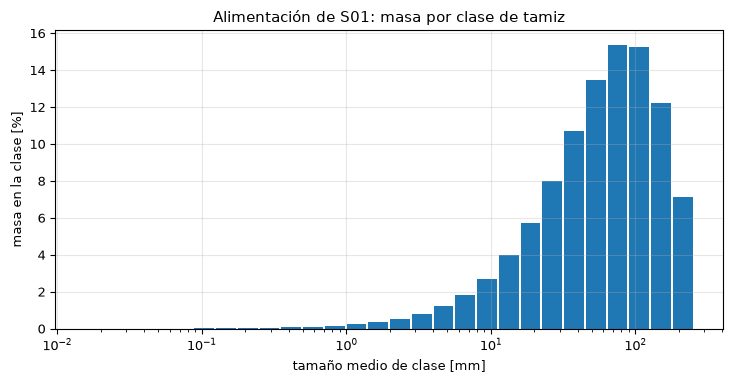

In [5]:
# Gráfico de barras de la masa por clase de la alimentación de S01 frente al tamaño medio de clase
fig, ax = plt.subplots()
widths = np.array(edges[:-1]) - np.array(edges[1:])
ax.bar(mids, np.array(feed.mass) * 100, width=widths * 0.9, align="center")
ax.set_xscale("log")
ax.set_xlabel("tamaño medio de clase [mm]")
ax.set_ylabel("masa en la clase [%]")
ax.set_title("Alimentación de S01: masa por clase de tamiz")
fig.tight_layout()
plt.show()

Las barras suben hasta un máximo entre 75 y 110 mm y bajan a ambos lados, la forma de una densidad de Weibull vista en un eje logarítmico. Como las clases son geométricas, el ancho de una barra en este eje es constante, así que alturas iguales son masas iguales. La figura muestra dónde está la masa de la alimentación y no qué tan fino será el producto; eso viene del quiebre en el tema 03.

**Paso 3, las dos lecturas.** El motor lee la curva en dos sentidos. `size_at_passing` toma una fracción y devuelve un tamaño: encuentra el par de bordes que contiene la fracción e interpola linealmente en el logaritmo del tamaño, $\ln x = \ln e_{inf} + t(\ln e_{sup} - \ln e_{inf})$ con $t$ la posición fraccional del pasante entre los valores de pasante de los dos bordes. `passing_at_size` va al revés, lineal en el logaritmo del tamaño. El par es coherente por construcción, y la celda lo verifica: leer un tamaño y luego su pasante devuelve la fracción.

In [6]:
# Ida y vuelta: fracción a tamaño a fracción, para varias fracciones
for p in (0.2, 0.5, 0.8, 0.95):
    x = size_at_passing(feed, p)
    print(f"p = {p:.2f} -> x = {x:8.3f} mm -> p = {passing_at_size(feed, x):.6f}")

p = 0.20 -> x =   24.786 mm -> p = 0.200000
p = 0.50 -> x =   63.944 mm -> p = 0.500000
p = 0.80 -> x =  126.033 mm -> p = 0.800000
p = 0.95 -> x =  200.613 mm -> p = 0.950000


**Paso 4, el error de interpolación.** Leer un tamaño entre dos bordes supone que la curva es una recta en el tamaño logarítmico ahí, lo que la curva verdadera no es. El error es entonces una propiedad de la malla, y una malla más fina debería reducirlo. Para medirlo necesitamos una referencia exacta de la misma alimentación truncada: la ley truncada tiene $R_T(x) = R(x)/R(256)$, de modo que su F80 resuelve $R(x) = 0{,}8\,R(256)$, que el oráculo invierte directamente, `law_size_at(0.8 * R(256), x63, m)`. La celda construye mallas con razones 2, $\sqrt2$, $2^{1/4}$ y $2^{1/8}$ (14, 28, 56 y 112 clases desde 256 mm) y compara el F80 del motor de cada una con esa referencia.

In [7]:
# Error de interpolación de F80 frente a la ley truncada exacta, para cuatro razones de malla
top = law_passing(256, X63, M)
exact_f80 = law_size_at(0.8 * top, X63, M)
rows = []
for ratio, classes in ((2.0, 14), (math.sqrt(2), 28), (2 ** 0.25, 56), (2 ** 0.125, 112)):
    grid = make_grid(256, classes, ratio)
    f80 = size_at_passing(make_feed(grid, X63, M), 0.8)
    rows.append((ratio, classes, f80, (f80 - exact_f80) / exact_f80 * 100))
    print(f"ratio {ratio:.4f}  classes {classes:3d}  F80 {f80:8.3f} mm  error {rows[-1][3]:+.4f} %")
print("F80 exacto de la ley truncada:", round(exact_f80, 3), "mm")

ratio 2.0000  classes  14  F80  126.042 mm  error +0.1122 %
ratio 1.4142  classes  28  F80  126.033 mm  error +0.1055 %
ratio 1.1892  classes  56  F80  125.983 mm  error +0.0654 %
ratio 1.0905  classes 112  F80  125.943 mm  error +0.0337 %
F80 exacto de la ley truncada: 125.901 mm


Desde la malla de raíz de dos en adelante, cada vez que se divide por la mitad el paso logarítmico el error baja más o menos a la mitad (0,11, 0,07 y 0,03 por ciento), así que la interpolación es de primer orden en el paso de la malla. La figura grafica el error contra la razón de la malla en un eje logarítmico. La curva no es una recta que pasa por cero porque el F80 verdadero también depende de dónde caen los bordes respecto del nivel de 80 por ciento; hay que leer la tendencia, no cada punto.

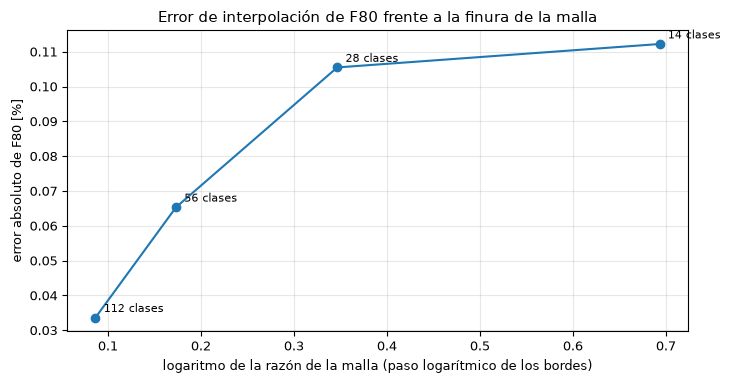

In [8]:
# Grafique el error de interpolación de F80 contra el logaritmo de la razón de la malla
fig, ax = plt.subplots()
ax.plot([math.log(r[0]) for r in rows], [abs(r[3]) for r in rows], "o-")
for ratio, classes, _, err in rows:
    ax.annotate(f"{classes} clases", (math.log(ratio), abs(err)), xytext=(6, 4), textcoords="offset points", fontsize=8)
ax.set_xlabel("logaritmo de la razón de la malla (paso logarítmico de los bordes)")
ax.set_ylabel("error absoluto de F80 [%]")
ax.set_title("Error de interpolación de F80 frente a la finura de la malla")
fig.tight_layout()
plt.show()

El error es a lo más 0,11 por ciento en la malla más gruesa y 0,03 por ciento en la más fina. Los tamaños del producto se leen entonces con una precisión mucho mejor que las otras incertidumbres del problema (el propio tamaño máximo de la alimentación, el mineral, la medición de planta), por eso la malla de raíz de dos es adecuada. Un error mayor se vería como una tendencia visible en esta figura; es una cota para una alimentación suave, no para una bimodal cuya parte empinada cae entre dos bordes.

**Paso 5, el oráculo en x63.** El oráculo enuncia un hecho sobre la ley, no sobre el motor: $R(x_{63}) = 1 - 1/e = 0{,}632$ para todo $m$. La alimentación del motor es la ley truncada, así que su pasante en $x_{63}$ es $R(x_{63})/R(256)$, mayor que 0,632 en el factor $1/R(256)$. Multiplicar el pasante del motor en $x_{63}$ por $R(256)$ debería devolver la constante del oráculo. La celda lo hace para seis alimentaciones de distinto $x_{63}$ y $m$ e imprime el valor crudo del motor, el corregido y el del oráculo.

In [9]:
# Pasante del motor en x63, crudo y corregido por el tamaño máximo de 256 mm, frente al 1 - 1/e del oráculo
cases = ((60, 0.9), (90, 1.2), (90, 2.0), (120, 1.5), (40, 0.7), (150, 2.5))
print("x63    m    motor crudo   corregido   oráculo")
for x63, m in cases:
    f = make_feed(edges, x63, m)
    raw_value = passing_at_size(f, x63)
    corrected = raw_value * law_passing(256, x63, m)
    print(f"{x63:4d} {m:5.1f} {raw_value:12.4f} {corrected:11.4f} {law_at_x63():9.4f}")

x63    m    motor crudo   corregido   oráculo
  60   0.9       0.6483      0.6321    0.6321
  90   1.2       0.6517      0.6322    0.6321
  90   2.0       0.6326      0.6324    0.6321
 120   1.5       0.6622      0.6328    0.6321
  40   0.7       0.6473      0.6307    0.6321
 150   2.5       0.6452      0.6308    0.6321


## Resultados

**Respuesta:** el error de interpolación de F80 es 0,1055 por ciento en la malla de raíz de dos del motor y baja a 0,0337 por ciento en una malla con cuatro veces más clases por factor de dos, de primer orden en el paso, así que el motor lee tamaños de su malla con un error muy inferior a las demás incertidumbres del problema. Frente al oráculo, el pasante del motor en $x_{63}$ no es 0,632 sino 0,6517 para S01, porque la malla descarta 3,00 por ciento de la masa de la ley; multiplicado por $R(256) = 0{,}9700$ da 0,6322, a menos de 0,0001 del $1 - 1/e = 0{,}6321$ del oráculo, y a menos de 0,0014 en las seis alimentaciones probadas (el resto es interpolación).

La primera figura muestra las masas de clase de la alimentación, y la segunda el error bajando con la malla. Un validador concluiría que la distribución de tamaños del motor es una discretización fiel de la ley de Rosin-Rammler truncada en el extremo de la malla, y que el oráculo coincide con ella solo después de considerar ese truncamiento. Lo que las comprobaciones no establecen es que la ley de Rosin-Rammler describa la alimentación de un chancador real; es un supuesto del producto, que la vía real del tema 05 declara como documentado (m = 0,9).

## Resumen

La malla es una serie geométrica, las masas son diferencias de la ley renormalizadas a 1, y los tamaños se leen por interpolación en el tamaño logarítmico, con un error de primer orden en el paso de la malla y de cerca de 0,1 por ciento en la resolución del motor. El oráculo en x63 se cumple para la alimentación del motor una vez que se considera el tamaño máximo de 256 mm. El tema siguiente lleva la distribución de tamaños a través del chancador: quiebre, clasificación y el cálculo de Whiten.

## Referencias

- Rosin, P., Rammler, E. (1933), The laws governing the fineness of powdered coal, Journal of the Institute of Fuel 7, 29-36. https://cir.nii.ac.jp/crid/1572543024341127296
- Whiten, W. J. (1972), The simulation of crushing plants with models developed using multiple spline regression, Journal of the South African Institute of Mining and Metallurgy 72(10), 257-264. https://www.saimm.co.za/Conferences/Apcom72/317-Whiten.pdf
- Napier-Munn, T. J., Morrell, S., Morrison, R. D., Kojovic, T. (1996), Mineral Comminution Circuits: Their Operation and Optimisation, JKMRC. https://search.worldcat.org/title/37081193